<a href="https://colab.research.google.com/github/LiliiaKuchvara/Python-DTA/blob/main/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D0%BA%D0%B0_%D0%BE%D0%BF%D0%B8%D1%81%D0%BE%D0%B2%D0%B0_%D1%81%D1%82%D0%B0%D1%82%D0%B8%D1%81%D1%82%D0%B8%D0%BA%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ✍️ Практика: описова статистика в Python

**Самостійна робота 34 завдання**

Сьогодні ви працюєте з даними сервісу доставки їжі **«Смачно Вдома»**: 2000 замовлень у чотирьох містах. Наприкінці — окремий датасет про вагу пачок кави на фабриці.

| Блок | Тема | Час |
|---|---|---|
| 1 | Знайомство з даними і типи ознак | 20 хв |
| 2 | Середнє, медіана, мода | 30 хв |
| 3 | Квантилі та перцентилі | 25 хв |
| 4 | Викиди | 25 хв |
| 5 | Міри розсіювання | 30 хв |
| 6 | Нормальний розподіл | 20 хв |
| 7 | Асиметрія і читання гістограм | 20 хв |
| 8 | Підсумковий міні-звіт | 15 хв |

---

### Як працювати з цим блокнотом

1. **Запускайте клітинки по черзі зверху вниз** (Shift + Enter). Спочатку обов'язково запустіть три службові клітинки в розділі «Підготовка».
2. **Пропуски `ВАШ_КОД`** у коді треба замінити на правильний код. Поки пропуск не заповнено, клітинка видасть помилку на кшталт `NameError: name 'ВАШ_КОД' is not defined`, і це нормально.
3. **Підказки відкриваються кліком** на «💡 Підказка 1». Спершу спробуйте самі, потім відкрийте першу підказку. Друга підказка майже містить відповідь, тож користуйтеся нею, якщо зовсім застрягли.
4. **Самоперевірка:** після більшості завдань є клітинка з `check(...)`. Запустіть її, і вона напише ✅ або ❌.
5. **Текстові відповіді:** клітинки «✍️ Ваша відповідь» двічі клацніть і напишіть відповідь своїми словами.
6. Завдання з ⭐ — **бонусні**. Якщо часу мало, їх можна пропустити.
7. Застрягли на завданні більше ніж на 10 хвилин — переходьте до наступного і поверніться пізніше.

> 💡 Відкрити в Google Colab: *File → Upload notebook*. Усі дані генеруються всередині блокнота.

---
## Підготовка

Запустіть три клітинки нижче: бібліотеки, дані та функції самоперевірки.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (9, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
pd.set_option('display.float_format', '{:.2f}'.format)

### Дані

| Колонка | Що означає |
|---|---|
| `order_id` | номер замовлення |
| `city` | місто |
| `restaurant_type` | тип кухні |
| `courier_type` | як доставляли: піший, велосипед, авто |
| `customer_level` | статус клієнта: Новий, Постійний, VIP |
| `items` | кількість страв у замовленні |
| `order_sum` | сума замовлення, грн |
| `distance_km` | відстань доставки, км |
| `delivery_min` | час доставки, хв |
| `tip_uah` | чайові кур'єру, грн |
| `rating` | оцінка клієнта 1–5 |
| `order_hour` | час замовлення (година доби, 13.5 = 13:30) |

Додатково: `sums_raw` — суми замовлень **з помилками введення** (блок 4), `packs` — вага пачок кави (блок 6).

In [2]:
rng = np.random.default_rng(2026)
n = 2000

# --- Основний датасет: замовлення сервісу доставки «Смачно Вдома» ---
courier = rng.choice(['Піший', 'Велосипед', 'Авто'], size=n, p=[0.20, 0.45, 0.35])
distance = np.where(courier == 'Піший',
                    rng.gamma(1.6, 0.6, n),
                    rng.gamma(2.2, 1.5, n)) + 0.3
per_km = np.select([courier == 'Піший', courier == 'Велосипед'], [12, 5], default=3.5)
traffic = np.where(courier == 'Авто', rng.gamma(1.2, 14, n), rng.gamma(2, 1.5, n))
delivery = rng.normal(18, 4, n).clip(8) + distance * per_km + traffic

restaurant = rng.choice(['Піца', 'Суші', 'Бургери', 'Українська кухня'], size=n, p=[0.32, 0.22, 0.26, 0.20])
mult = pd.Series(restaurant).map({'Піца': 1.1, 'Суші': 1.4, 'Бургери': 0.85, 'Українська кухня': 1.0}).to_numpy()

lunch = rng.normal(13, 0.9, int(n * 0.45))
dinner = rng.normal(19.5, 1.1, n - int(n * 0.45))
hours = np.concatenate([lunch, dinner])
rng.shuffle(hours)

tips = np.where(rng.random(n) < 0.55, 0, np.round(rng.gamma(2, 15, n)))

df = pd.DataFrame({
    'order_id':        np.arange(10001, 10001 + n),
    'city':            rng.choice(['Київ', 'Львів', 'Харків', 'Одеса'], size=n, p=[0.42, 0.22, 0.18, 0.18]),
    'restaurant_type': restaurant,
    'courier_type':    courier,
    'customer_level':  rng.choice(['Новий', 'Постійний', 'VIP'], size=n, p=[0.35, 0.50, 0.15]),
    'items':           rng.poisson(1.5, n) + 1,
    'order_sum':       np.round(rng.lognormal(5.95, 0.45, n) * mult),
    'distance_km':     np.round(distance, 1),
    'delivery_min':    np.round(delivery, 1),
    'tip_uah':         tips,
    'rating':          rng.choice([1, 2, 3, 4, 5], size=n, p=[0.04, 0.06, 0.15, 0.33, 0.42]),
    'order_hour':      np.round(hours.clip(10, 23.5), 2),
})

# --- Сирі суми замовлень з помилками введення (для блоку 4) ---
sums_raw = df['order_sum'].copy()
sums_raw.iloc[[15, 340, 777, 1200]] = 99999      # касир вбив зайві цифри
sums_raw.iloc[[500]] = -450                      # повернення записали як замовлення
sums_raw.iloc[[901, 1500]] = 0                   # тестові замовлення

# --- Другий датасет: вага пачок кави на фабриці (для блоку 6) ---
packs = pd.Series(np.round(rng.normal(250, 3, 1500), 1), name='weight_g')

print('Датасет df:', df.shape, '| sums_raw:', sums_raw.shape, '| packs:', packs.shape)

Датасет df: (2000, 12) | sums_raw: (2000,) | packs: (1500,)


In [3]:
# ⚙️ Службова клітинка: функції для самоперевірки. Просто запустіть її, змінювати нічого не потрібно.
ANSWERS = {
    '1.1': [2000.0, 12.0],
    '1.3': ['Київ'],
    '1.4': [0.154],
    '2.1': [452.892, 403.5],
    '2.2': ['Піца', 'Велосипед'],
    '2.3': [13.8215, 0.0, 0.0],
    '2.4': [542.0],
    '2.5': [393.75, 275.0],
    '3.1': [31.2, 38.7, 47.925],
    '3.2': [59.2, 67.8],
    '3.3': [0.6805],
    '3.4': [68.82],
    '4.1': [-450.0, 99999.0],
    '4.2': [650.946, 403.5, 452.757652],
    '4.3': [86.0],
    '4.4': [433.795556],
    '5.1': [123.1, 195.392169, 13.978275, 16.725],
    '5.2': [24.5, 4.949747],
    '5.3': [19.6, 24.5, 24.5],
    '5.4': ['Піший'],
    '5.5': [0.505339, 0.340061],
    '6.1': [249.987667, 3.067317],
    '6.2': [0.683333, 0.956, 0.994667],
    '6.3': [-2.930139],
    '6.4': [0.051968, 0.051333],
    '7.1': ['rating'],
    '7.4': [13.0, 19.0],
}
_TYPES = {"city": "номінальна", "restaurant_type": "номінальна", "courier_type": "номінальна", "customer_level": "порядкова", "items": "дискретна", "order_sum": "неперервна", "delivery_min": "неперервна", "rating": "порядкова"}

def check(task, *values):
    expected = ANSWERS[task]
    if len(values) != len(expected):
        print(f'⚠️ Очікую {len(expected)} значення(нь), а отримала функція {len(values)}.')
        return
    ok = True
    for v, e in zip(values, expected):
        if isinstance(e, str):
            good = str(v).strip().lower() == e.lower()
        else:
            try:
                good = abs(float(v) - e) <= max(0.01, abs(e) * 0.005)
            except (TypeError, ValueError):
                good = False
        ok = ok and good
    if ok:
        print(f'✅ Завдання {task}: правильно! Можна рухатися далі.')
    else:
        print(f'❌ Завдання {task}: поки не збігається. Перевірте код і відкрийте підказку.')

def check_types(my_types):
    wrong = [col for col, t in _TYPES.items() if str(my_types.get(col, '')).strip().lower() != t]
    if not wrong:
        print('✅ Завдання 1.2: усі типи визначено правильно!')
    else:
        print(f'❌ Правильно {len(_TYPES) - len(wrong)} з {len(_TYPES)}. Перегляньте: {", ".join(wrong)}')

---

## Блок 1. Знайомство з даними і типи ознак (⏱ 20 хв)

Перш ніж щось рахувати, треба зрозуміти, які дані перед нами і якого типу кожна колонка.

**Нагадування про типи ознак:**

| Тип | Що означає | Приклад |
|---|---|---|
| **Номінальна** | категорії без порядку | місто, колір |
| **Порядкова** | категорії з природним порядком | розмір S/M/L, оцінка 1–5 |
| **Дискретна** (кількісна) | цілі числа, які ми **рахуємо** | кількість товарів |
| **Неперервна** (кількісна) | будь-яке значення, яке ми **вимірюємо** | вага, час, сума |

### Завдання 1.1. Розмір таблиці

Дізнайтеся, скільки рядків і скільки колонок у таблиці `df`. Збережіть їх у змінні `n_rows` і `n_cols`. Потім виведіть перші 5 рядків таблиці.

<details>
<summary><b>💡 Підказка 1</b></summary>

У кожного датафрейму є атрибут `.shape` — він повертає пару чисел: (кількість рядків, кількість колонок). Перші рядки показує метод `.head()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Пару чисел можна одразу «розпакувати» у дві змінні:

```python
n_rows, n_cols = df.shape
```

</details>

In [5]:
n_rows, n_cols = df.shape
print('Рядків:', n_rows, '| Колонок:', n_cols)

df.head()

Рядків: 2000 | Колонок: 12


,order_id,city,restaurant_type,courier_type,customer_level,items,order_sum,distance_km,delivery_min,tip_uah,rating,order_hour
0,10001,Київ,Піца,Піший,Постійний,2,615.00,1.10,34.10,0.00,4,13.50
1,10002,Харків,Піца,Велосипед,Постійний,4,194.00,7.00,58.10,12.00,4,14.08
2,10003,Київ,Суші,Велосипед,Постійний,3,424.00,0.80,28.60,0.00,5,20.76
3,10004,Львів,Суші,Велосипед,Постійний,2,835.00,17.60,110.00,0.00,4,18.82
4,10005,Київ,Піца,Велосипед,Новий,2,466.00,5.90,51.00,12.00,4,18.88


In [6]:
check('1.1', n_rows, n_cols)

✅ Завдання 1.1: правильно! Можна рухатися далі.


### Завдання 1.2. Визначте тип кожної ознаки

Для кожної колонки у словнику `my_types` впишіть її тип одним із чотирьох слів: `'номінальна'`, `'порядкова'`, `'дискретна'`, `'неперервна'`.

Опис колонок: `city` — місто, `restaurant_type` — тип кухні, `courier_type` — як доставляли, `customer_level` — статус клієнта (Новий → Постійний → VIP), `items` — кількість страв, `order_sum` — сума замовлення в грн, `delivery_min` — час доставки в хв, `rating` — оцінка 1–5.

<details>
<summary><b>💡 Підказка 1</b></summary>

Поставте собі два питання до кожної колонки:

1. Це **числа**, з якими має сенс рахувати (додавати, усереднювати), чи **назви категорій**?
2. Якщо категорії — чи є між ними **природний порядок**?

Якщо число — ми його **рахуємо штуками** (дискретна) чи **вимірюємо** (неперервна)?

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Підказка до складних випадків:

- `rating` записаний числами, але це **оцінка**: різниця між 1 і 2 не обов'язково така сама, як між 4 і 5. Це категорії з порядком.
- `customer_level`: Новий < Постійний < VIP — порядок є.
- `items` — страви рахують штуками: 1, 2, 3…

</details>

In [7]:
my_types = {
    'city':            'ВАШ_КОД',
    'restaurant_type': 'ВАШ_КОД',
    'courier_type':    'ВАШ_КОД',
    'customer_level':  'ВАШ_КОД',
    'items':           'ВАШ_КОД',
    'order_sum':       'ВАШ_КОД',
    'delivery_min':    'ВАШ_КОД',
    'rating':          'ВАШ_КОД',
}

In [9]:
check_types(my_types)

city = my_types['city']
restaurant_type = my_types['restaurant_type']
courier_type = my_types['courier_type']
customer_level = my_types['customer_level']
items = my_types['items']
order_sum = my_types['order_sum']
delivery_min = my_types['delivery_min']
rating = my_types['rating']

❌ Правильно 0 з 8. Перегляньте: city, restaurant_type, courier_type, customer_level, items, order_sum, delivery_min, rating


### Завдання 1.3. Найпопулярніше місто

Порахуйте, скільки замовлень зроблено в кожному місті. Збережіть у змінну `top_city` назву міста з найбільшою кількістю замовлень.

<details>
<summary><b>💡 Підказка 1</b></summary>

Для номінальної ознаки рахуємо частоти методом `.value_counts()`. Він одразу сортує категорії від найчастішої до найрідшої.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Назва першого (найчастішого) значення — це перший елемент індексу:

```python
city_counts = df['city'].value_counts()
top_city = city_counts.index[0]
```

Або одразу через моду: `df['city'].mode()[0]`.

</details>

In [11]:
city_counts = df['city'].value_counts()
print(city_counts)

top_city = city_counts.index[0]
print('Найпопулярніше місто:', top_city)

city
Київ      820
Львів     443
Харків    383
Одеса     354
Name: count, dtype: int64
Найпопулярніше місто: Київ


In [15]:
check('1.3', top_city)

✅ Завдання 1.3: правильно! Можна рухатися далі.


### Завдання 1.4. Статус клієнтів у правильному порядку

Виведіть кількість замовлень для кожного статусу клієнта **у логічному порядку**: Новий → Постійний → VIP (а не за частотою). Збережіть у `vip_share` частку замовлень від VIP-клієнтів (число від 0 до 1).

<details>
<summary><b>💡 Підказка 1</b></summary>

`value_counts()` сортує за частотою, а для порядкової ознаки зручніше бачити категорії в їхньому природному порядку. Переставити рядки в потрібному порядку можна методом `.reindex([...])`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
level_counts = df['customer_level'].value_counts().reindex(['Новий', 'Постійний', 'VIP'])
```

Частку можна отримати з `value_counts(normalize=True)` або так: `(df['customer_level'] == 'VIP').mean()` — середнє з True/False дорівнює частці True.

</details>

In [13]:
level_counts = df['customer_level'].value_counts().reindex(['Новий', 'Постійний', 'VIP'])

print(level_counts)

vip_share = (df['customer_level'] == 'VIP').mean()
print(f'Частка VIP: {vip_share:.1%}')

customer_level
Новий        714
Постійний    978
VIP          308
Name: count, dtype: int64
Частка VIP: 15.4%


In [14]:
check('1.4', vip_share)

✅ Завдання 1.4: правильно! Можна рухатися далі.


---

## Блок 2. Середнє, медіана, мода (⏱ 30 хв)

**Нагадування:**
- **Середнє** — сума всіх значень ÷ кількість. Чутливе до дуже великих і дуже малих значень.
- **Медіана** — значення посередині після сортування. Половина значень менша, половина більша.
- **Мода** — значення, яке трапляється найчастіше. Єдина міра центру для категорій.

| Функція pandas | Що рахує |
|---|---|
| `df['col'].mean()` | середнє |
| `df['col'].median()` | медіана |
| `df['col'].mode()[0]` | мода (перша, якщо їх кілька) |

### Завдання 2.1. Середня і медіанна сума замовлення

Порахуйте середню і медіанну суму замовлення (`order_sum`). Збережіть у змінні `mean_sum` і `median_sum`. Що більше — середнє чи медіана?

<details>
<summary><b>💡 Підказка 1</b></summary>

Виберіть колонку через `df['order_sum']` і викличте відповідні методи: `.mean()` і `.median()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
mean_sum = df['order_sum'].mean()
median_sum = df['order_sum'].median()
```

</details>

In [16]:
mean_sum = df['order_sum'].mean()
median_sum = df['order_sum'].median()

print(f'Середня сума:  {mean_sum:.0f} грн')
print(f'Медіанна сума: {median_sum:.0f} грн')

Середня сума:  453 грн
Медіанна сума: 404 грн


In [17]:
check('2.1', mean_sum, median_sum)

✅ Завдання 2.1: правильно! Можна рухатися далі.


**✍️ Середнє більше за медіану. Що це говорить про дані? Чи є серед замовлень невелика кількість дуже дорогих?**

*Ваша відповідь:* _(двічі клацніть, щоб написати)_

### Завдання 2.2. Найпопулярніша кухня і спосіб доставки

Знайдіть моду для колонок `restaurant_type` і `courier_type`. Збережіть у `top_restaurant` і `top_courier`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Мода — метод `.mode()`. Він повертає **список** значень (бо мод може бути кілька), тому беремо перше: `[0]`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
top_restaurant = df['restaurant_type'].mode()[0]
```

</details>

In [18]:
top_restaurant = df['restaurant_type'].mode()[0]
top_courier = df['courier_type'].mode()[0]

print('Найпопулярніша кухня:', top_restaurant)
print('Найчастіший кур\'єр:', top_courier)

Найпопулярніша кухня: Піца
Найчастіший кур'єр: Велосипед


In [19]:
check('2.2', top_restaurant, top_courier)

✅ Завдання 2.2: правильно! Можна рухатися далі.


### Завдання 2.3. Чайові: три різні «типові» значення

Для колонки `tip_uah` (чайові кур'єру, грн) порахуйте середнє, медіану і моду. Збережіть у `tip_mean`, `tip_median`, `tip_mode`. Подумайте, чому вони так сильно різняться.

<details>
<summary><b>💡 Підказка 1</b></summary>

Використайте ті самі три методи, що й вище. Щоб зрозуміти результат, подивіться, яка частка замовлень взагалі без чайових: `(df['tip_uah'] == 0).mean()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
tip_mean = df['tip_uah'].mean()
tip_median = df['tip_uah'].median()
tip_mode = df['tip_uah'].mode()[0]
```

Якщо більше половини клієнтів не залишають чайових, то медіана і мода дорівнюватимуть 0.

</details>

In [20]:
tip_mean = df['tip_uah'].mean()
tip_median = df['tip_uah'].median()
tip_mode = df['tip_uah'].mode()[0]

print(f'Середнє: {tip_mean:.1f} | Медіана: {tip_median} | Мода: {tip_mode}')
print(f'Частка замовлень без чайових: {(df["tip_uah"] == 0).mean():.0%}')

Середнє: 13.8 | Медіана: 0.0 | Мода: 0.0
Частка замовлень без чайових: 54%


In [21]:
check('2.3', tip_mean, tip_median, tip_mode)

✅ Завдання 2.3: правильно! Можна рухатися далі.


**✍️ Кур'єр каже: «У середньому мені залишають ~14 грн чайових». Чи коректне це твердження? Яке число краще описує типову ситуацію?**

*Ваша відповідь:* _Твердження кур’єра математично коректне: середнє значення чайових становить приблизно 13,8 грн на одне замовлення. Але воно не дуже добре описує типову ситуацію, оскільки 54% замовлень взагалі не мають чайових.

Медіана і мода дорівнюють 0 грн, тобто найтиповіша ситуація - клієнт не залишає чайових. Середнє вище через те, що деякі клієнти залишають більші суми, які підвищують загальний показник.

Тому для опису типового замовлення краще використовувати медіану - 0 грн, а середнє - для оцінки загальної суми чайових у розрахунку на одне замовлення.

### Завдання 2.4. Сума замовлення за типом кухні

Порахуйте середню і медіанну суму замовлення для кожного типу кухні. Збережіть у `sushi_median` медіанну суму замовлення суші.

<details>
<summary><b>💡 Підказка 1</b></summary>

Для розрахунку «по групах» використовують `groupby`: спочатку групуємо за колонкою, потім вибираємо колонку для розрахунку, потім указуємо функції через `.agg([...])`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
by_rest = df.groupby('restaurant_type')['order_sum'].agg(['mean', 'median'])
sushi_median = by_rest.loc['Суші', 'median']
```

`.loc[рядок, колонка]` дістає одне значення з таблиці.

</details>

In [22]:
by_rest = df.groupby('restaurant_type')['order_sum'].agg(['mean', 'median'])
print(by_rest)

sushi_median = by_rest.loc['Суші', 'median']

                   mean  median
restaurant_type                
Бургери          352.59  317.50
Піца             458.65  410.00
Суші             596.88  542.00
Українська кухня 414.27  380.00


In [23]:
check('2.4', sushi_median)

✅ Завдання 2.4: правильно! Можна рухатися далі.


### Завдання 2.5. Середнє і медіана «вручну»

Не використовуючи `numpy` і `pandas`, порахуйте середнє і медіану для 8 замовлень зі списку `small`. Збережіть у `manual_mean` і `manual_median`.

<details>
<summary><b>💡 Підказка 1</b></summary>

- Середнє: `sum(список) / len(список)`.
- Медіана: спершу відсортуйте список функцією `sorted()`. Значень **парна** кількість (8), тому медіана — це середнє двох центральних.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Для 8 значень центральні мають індекси **3 і 4** (у Python рахуємо з нуля):

```python
s = sorted(small)
manual_median = (s[3] + s[4]) / 2
```

Універсально: `(s[len(s)//2 - 1] + s[len(s)//2]) / 2`.

</details>

In [24]:
small = [300, 220, 1200, 250, 410, 180, 340, 250]

manual_mean = sum(small) / len(small)

s = sorted(small)
print('Відсортовано:', s)
manual_median = (s[3] + s[4]) / 2

print('Середнє:', manual_mean, '| Медіана:', manual_median)

Відсортовано: [180, 220, 250, 250, 300, 340, 410, 1200]
Середнє: 393.75 | Медіана: 275.0


In [25]:
check('2.5', manual_mean, manual_median)

✅ Завдання 2.5: правильно! Можна рухатися далі.


---

## Блок 3. Квантилі та перцентилі (⏱ 25 хв)

**Нагадування:**
- **Квантиль рівня q** — значення, нижче якого лежить частка q даних. Квантиль 0.9 = **90-й перцентиль** = **p90**.
- **Квартилі:** Q1 = 25%, Q2 = 50% (медіана), Q3 = 75%.
- «p90 часу доставки = 60 хв» означає: **90% замовлень доставлено не довше ніж за 60 хв**.

| Код | Що робить |
|---|---|
| `df['col'].quantile(0.9)` | один квантиль |
| `df['col'].quantile([0.25, 0.5, 0.75])` | кілька квантилів одразу |
| `df['col'].describe()` | основні статистики разом із квартилями |

### Завдання 3.1. Квартилі часу доставки

Знайдіть Q1, медіану і Q3 для `delivery_min`. Збережіть у `q1_del`, `med_del`, `q3_del`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Метод `.quantile()` приймає частку від 0 до 1. Для Q1 — 0.25, для медіани — 0.5, для Q3 — 0.75.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Можна три окремі рядки:

```python
q1_del = df['delivery_min'].quantile(0.25)
```

або одним рядком із розпакуванням:

```python
q1_del, med_del, q3_del = df['delivery_min'].quantile([0.25, 0.5, 0.75])
```

</details>

In [27]:
q1_del, med_del, q3_del = df['delivery_min'].quantile([0.25, 0.5, 0.75])

print(f'Q1 = {q1_del:.1f} хв | Медіана = {med_del:.1f} хв | Q3 = {q3_del:.1f} хв')

Q1 = 31.2 хв | Медіана = 38.7 хв | Q3 = 47.9 хв


In [28]:
check('3.1', q1_del, med_del, q3_del)

✅ Завдання 3.1: правильно! Можна рухатися далі.


**✍️ Поясніть простими словами, що означає Q3 часу доставки.**

*Ваша відповідь:* _(двічі клацніть, щоб написати)_

### Завдання 3.2. p90 і p95 часу доставки

Знайдіть 90-й і 95-й перцентилі часу доставки. Збережіть у `p90_del` і `p95_del`.

<details>
<summary><b>💡 Підказка 1</b></summary>

90-й перцентиль — це квантиль рівня 0.90, а 95-й — рівня 0.95.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
p90_del = df['delivery_min'].quantile(0.90)
```

</details>

In [29]:
p90_del = df['delivery_min'].quantile(0.90)
p95_del = df['delivery_min'].quantile(0.95)

print(f'p90 = {p90_del:.1f} хв | p95 = {p95_del:.1f} хв')

p90 = 59.2 хв | p95 = 67.8 хв


In [30]:
check('3.2', p90_del, p95_del)

✅ Завдання 3.2: правильно! Можна рухатися далі.


### Завдання 3.3. Виконання обіцянки «доставка за 45 хвилин»

Сервіс обіцяє доставку за 45 хвилин. Яку частку замовлень доставили вчасно (≤ 45 хв)? Збережіть у `sla_share` (число від 0 до 1).

<details>
<summary><b>💡 Підказка 1</b></summary>

Порівняння `df['delivery_min'] <= 45` дає колонку з True/False. Середнє з True/False = частка True, бо True рахується як 1, а False — як 0.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
sla_share = (df['delivery_min'] <= 45).mean()
```

</details>

In [31]:
sla_share = (df['delivery_min'] <= 45).mean()
print(f'Доставлено вчасно: {sla_share:.1%}')

Доставлено вчасно: 68.0%


In [32]:
check('3.3', sla_share)

✅ Завдання 3.3: правильно! Можна рухатися далі.


**✍️ Чи виконує сервіс свою обіцянку? Якщо компанія хоче, щоб 90% замовлень встигали вчасно, який час доставки чесно писати в рекламі (дивіться результат 3.2)?**

*Ваша відповідь:* _Якщо частка sla_share менша за 90%, сервіс поки що не виконує свою обіцянку для цільових 90% замовлень. Якщо вона дорівнює або перевищує 90%, то виконує.

Якщо компанія хоче, щоб 90% замовлень доставляли вчасно, чесно рекламувати час, що відповідає 90-му перцентилю часу доставки (delivery_min). Це означає, що 90% замовлень будуть доставлені за цей час або швидше.

Наприклад, якщо 90-й перцентиль дорівнює 55 хвилинам, краще обіцяти доставку до 55 хвилин, а не до 45.

### Завдання 3.4. p90 для кожного типу кур'єра

Порахуйте 90-й перцентиль часу доставки окремо для кожного типу кур'єра. Збережіть у `p90_car` значення для типу «Авто».

<details>
<summary><b>💡 Підказка 1</b></summary>

Квантиль теж можна рахувати по групах: `groupby(...)[...]` і потім `.quantile(0.9)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
p90_by_courier = df.groupby('courier_type')['delivery_min'].quantile(0.9)
p90_car = p90_by_courier['Авто']
```

</details>

In [33]:
p90_by_courier = df.groupby('courier_type')['delivery_min'].quantile(0.9)
print(p90_by_courier)

p90_car = p90_by_courier['Авто']

courier_type
Авто        68.82
Велосипед   53.66
Піший       49.25
Name: delivery_min, dtype: float64


In [34]:
check('3.4', p90_car)

✅ Завдання 3.4: правильно! Можна рухатися далі.


### Завдання 3.5. Читаємо describe()

Виведіть `describe()` для колонки `distance_km` і дайте відповідь на питання нижче.

<details>
<summary><b>💡 Підказка 1</b></summary>

Просто викличте `df['distance_km'].describe()`. Рядки `25%`, `50%`, `75%` — це квартилі.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
df['distance_km'].describe()
```

Рядок `count` — кількість значень, `std` — стандартне відхилення, `min`/`max` — крайні значення.

</details>

In [35]:
df['distance_km'].describe()

,distance_km
count,2000.00
mean,3.12
std,2.16
min,0.30
25%,1.50
50%,2.60
75%,4.20
max,17.60


**✍️ Яка медіанна відстань доставки? Яка частка замовлень їде далі за 4 км приблизно (подивіться на 75%)? Чи є щось підозріле в min і max?**

*Ваша відповідь:* _Медіанна відстань доставки - це значення 50% у результаті describe(). Воно показує, що половина замовлень має меншу відстань, а половина - більшу.

Якщо показник 75% приблизно дорівнює 4 км, то близько 25% замовлень долають понад 4 км.

У значеннях min і max варто перевірити можливі аномалії: мінімальна відстань може бути нульовою або надто малою, а максимальна - незвично великою для звичайної доставки. Такі значення можуть свідчити про помилки в даних або нетипові замовлення.

Щоб дати точну відповідь із конкретною медіаною та оцінкою підозрілих значень, потрібно побачити результат df['distance_km'].describe().


---

## Блок 4. Викиди (⏱ 25 хв)

**Нагадування:**
- **Викид** — значення, яке сильно відрізняється від решти. Це може бути помилка, рідкісна подія або інша група.
- **Середнє чутливе** до викидів, **медіана — стійка**.
- **Правило 1.5 × IQR:** потенційні викиди — значення нижче `Q1 − 1.5·IQR` або вище `Q3 + 1.5·IQR`, де `IQR = Q3 − Q1`.

У цьому блоці працюємо з `sums_raw` — це ті самі суми замовлень, але **з кількома помилками введення**, як у справжніх «сирих» даних.

### Завдання 4.1. Знайдіть підозрілі значення

Знайдіть мінімум і максимум у `sums_raw`. Збережіть у `raw_min` і `raw_max`. Виведіть також 10 найменших і 10 найбільших значень.

<details>
<summary><b>💡 Підказка 1</b></summary>

`.min()` і `.max()` дають крайні значення. Щоб побачити кілька найменших або найбільших, відсортуйте: `.sort_values()` і візьміть `.head(10)` або `.tail(10)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
raw_min = sums_raw.min()
raw_max = sums_raw.max()
print(sums_raw.sort_values().head(10))
print(sums_raw.sort_values().tail(10))
```

</details>

In [37]:
raw_min = sums_raw.min()
raw_max = sums_raw.max()
print('Мінімум:', raw_min, '| Максимум:', raw_max)

print(sums_raw.sort_values().head(10))
print(sums_raw.sort_values(ascending=False).head(10))

Мінімум: -450.0 | Максимум: 99999.0
500    -450.00
901       0.00
1500      0.00
54       97.00
350     101.00
1079    105.00
987     107.00
1608    108.00
530     109.00
818     111.00
Name: order_sum, dtype: float64
15     99999.00
340    99999.00
1200   99999.00
777    99999.00
1659    1847.00
535     1775.00
893     1769.00
1344    1585.00
412     1570.00
1031    1549.00
Name: order_sum, dtype: float64


In [38]:
check('4.1', raw_min, raw_max)

✅ Завдання 4.1: правильно! Можна рухатися далі.


**✍️ Які значення явно є помилками? Чому сума замовлення не може бути від'ємною або нульовою?**

*Ваша відповідь:* _Явними помилками є від’ємні та нульові суми замовлень, а також підозріло великі значення. Сума замовлення не може бути від’ємною, оскільки клієнт платить за товари, а не отримує гроші. Нульова сума також підозріла, адже замовлення зазвичай має певну вартість. Дуже великі суми можуть виникати через помилки введення, наприклад зайвий нуль. Такі значення потрібно перевірити перед аналізом.

### Завдання 4.2. Як помилки зіпсували середнє

Порахуйте середнє і медіану для `sums_raw` (з помилками). Потім залиште лише реалістичні значення — більші за 0 і менші за 20 000 — і порахуйте середнє ще раз. Збережіть у `raw_mean`, `raw_median`, `clean_mean`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Фільтрація Series: `sums_raw[умова]`. Дві умови з'єднуються знаком `&`, і **кожна умова має бути в дужках**.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
clean = sums_raw[(sums_raw > 0) & (sums_raw < 20000)]
clean_mean = clean.mean()
```

</details>

In [40]:
raw_mean = sums_raw.mean()
raw_median = sums_raw.median()

clean = sums_raw[(sums_raw > 0) & (sums_raw < 20000)]
clean_mean = clean.mean()

print(f'З помилками:  середнє = {raw_mean:.0f}, медіана = {raw_median:.0f}')
print(f'Без помилок: середнє = {clean_mean:.0f}, медіана = {clean.median():.0f}')
print('Видалено рядків:', len(sums_raw) - len(clean))

З помилками:  середнє = 651, медіана = 404
Без помилок: середнє = 453, медіана = 403
Видалено рядків: 7


In [41]:
check('4.2', raw_mean, raw_median, clean_mean)

✅ Завдання 4.2: правильно! Можна рухатися далі.


**✍️ Скільки рядків ми видалили і як змінилось середнє? А медіана? Який висновок?**

*Ваша відповідь:* _Bидалили 7 рядків із помилковими значеннями. Після очищення середнє зменшилося з 651 грн до 453 грн, тобто на 198 грн. Медіана майже не змінилася: була 404 грн, стала 403 грн. Це свідчить про те, що викиди суттєво спотворювали середнє, але майже не впливали на медіану. Отже, медіана є стійкішою до екстремальних значень і краще описує типову суму замовлення за наявності помилок у даних.

### Завдання 4.3. Правило 1.5 × IQR

Застосуйте правило 1.5 × IQR до **чистої** колонки `df['order_sum']`. Знайдіть нижню і верхню межу і порахуйте кількість потенційних викидів. Збережіть кількість у `n_outliers`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Кроки:

1. Знайдіть Q1 і Q3.
2. `iqr = q3 - q1`
3. `lower = q1 - 1.5 * iqr`, `upper = q3 + 1.5 * iqr`
4. Відфільтруйте значення, які **менші за lower АБО більші за upper**. «АБО» в pandas позначається знаком `|`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
q1, q3 = df['order_sum'].quantile([0.25, 0.75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = df['order_sum'][(df['order_sum'] < lower) | (df['order_sum'] > upper)]
n_outliers = len(outliers)
```

</details>

In [42]:
q1, q3 = df['order_sum'].quantile([0.25, 0.75])
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df['order_sum'][
    (df['order_sum'] < lower) | (df['order_sum'] > upper)
]
n_outliers = len(outliers)

print('Q1:', q1, '| Q3:', q3)
print('IQR:', iqr)
print('Нижня межа:', lower, '| Верхня межа:', upper)
print('Кількість потенційних викидів:', n_outliers)

Q1: 297.75 | Q3: 553.0
IQR: 255.25
Нижня межа: -85.125 | Верхня межа: 935.875
Кількість потенційних викидів: 86


In [ ]:
check('4.3', n_outliers)

**✍️ Ці «викиди» — помилки, які треба видалити? Чи це справжні дорогі замовлення?**

*Ваша відповідь:* _Не обов’язково. Ці 86 значень є потенційними викидами за правилом 1,5 × IQR, але це не означає, що вони помилкові. Вони можуть бути справжніми дорогими замовленнями. Перед видаленням потрібно перевірити ці значення та з’ясувати причину їх появи. Якщо це реальні замовлення, їх варто залишити, оскільки вони містять важливу інформацію про клієнтів. Видаляти потрібно лише підтверджені помилки.

### Завдання 4.4. Усічене середнє ⭐ *бонус*

Порахуйте усічене середнє для `sums_raw` (з помилками), відкинувши 5% найменших і 5% найбільших значень. Збережіть у `trim_raw` і порівняйте з `raw_mean` та `clean_mean`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Функція `stats.trim_mean(дані, частка)` з бібліотеки `scipy` відкидає вказану частку з кожного боку.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
trim_raw = stats.trim_mean(sums_raw, 0.05)
```

</details>

In [43]:
trim_raw = stats.trim_mean(sums_raw, 0.05)
print(f'Звичайне середнє (з помилками): {raw_mean:.0f}')
print(f'Усічене середнє (з помилками):  {trim_raw:.0f}')
print(f'Середнє чистих даних:            {clean_mean:.0f}')

Звичайне середнє (з помилками): 651
Усічене середнє (з помилками):  434
Середнє чистих даних:            453


In [44]:
check('4.4', trim_raw)

✅ Завдання 4.4: правильно! Можна рухатися далі.


---

## Блок 5. Міри розсіювання (⏱ 30 хв)

**Нагадування:**

| Міра | Формула | Чутлива до викидів? |
|---|---|:---:|
| Розмах | max − min | ✅ дуже |
| Дисперсія | $s^2 = \frac{\sum (x_i - \bar{x})^2}{n-1}$ | ✅ так |
| Стандартне відхилення | $s = \sqrt{s^2}$ | ✅ так |
| IQR | Q3 − Q1 | ❌ ні |

⚠️ `numpy` за замовчуванням ділить на **n**, а `pandas` — на **n − 1**. Для вибірки в `numpy` пишіть `ddof=1`.

### Завдання 5.1. Чотири міри розкиду часу доставки

Для `delivery_min` порахуйте розмах, дисперсію, стандартне відхилення та IQR. Збережіть у `range_del`, `var_del`, `std_del`, `iqr_del`.

<details>
<summary><b>💡 Підказка 1</b></summary>

- Розмах: `max() - min()`
- Дисперсія: `.var()`
- Стандартне відхилення: `.std()`
- IQR: `quantile(0.75) - quantile(0.25)`

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
d = df['delivery_min']
range_del = d.max() - d.min()
var_del = d.var()
std_del = d.std()
iqr_del = d.quantile(0.75) - d.quantile(0.25)
```

</details>

In [45]:
d = df['delivery_min']

range_del = d.max() - d.min()
var_del = d.var()
std_del = d.std()
iqr_del = d.quantile(0.75) - d.quantile(0.25)

print(f'Розмах: {range_del:.1f} хв')
print(f'Дисперсія: {var_del:.1f} хв²')
print(f'Станд. відхилення: {std_del:.1f} хв')
print(f'IQR: {iqr_del:.1f} хв')

Розмах: 123.1 хв
Дисперсія: 195.4 хв²
Станд. відхилення: 14.0 хв
IQR: 16.7 хв


In [46]:
check('5.1', range_del, var_del, std_del, iqr_del)

✅ Завдання 5.1: правильно! Можна рухатися далі.


**✍️ Чому дисперсію незручно інтерпретувати, а стандартне відхилення — зручно?**

*Ваша відповідь:* _Дисперсію незручно інтерпретувати, тому що вона вимірюється у квадратних одиницях — у нашому випадку хв², а не хвилинах. Стандартне відхилення є квадратним коренем із дисперсії, тому вимірюється в тих самих одиницях, що й початкові дані. Наприклад, стандартне відхилення часу доставки становить 14 хвилин, тому його легше зрозуміти та пояснити, ніж дисперсію 195,4 хв².

### Завдання 5.2. Дисперсія крок за кроком

Для 5 доставок зі списку `x` порахуйте дисперсію вручну за формулою. Заповніть таблицю відхилень, а потім збережіть у `manual_var` дисперсію (ділимо на n − 1), а в `manual_std` — стандартне відхилення.

<details>
<summary><b>💡 Підказка 1</b></summary>

Кроки:

1. Знайдіть середнє.
2. Для кожного значення: відхилення = значення − середнє.
3. Піднесіть кожне відхилення до квадрата.
4. Складіть квадрати.
5. Поділіть суму на (n − 1).
6. Стандартне відхилення = корінь із дисперсії: `np.sqrt(...)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

З масивом `numpy` можна робити операції з усіма елементами одразу:

```python
dev = x - mean_x        # відхилення для всіх
sq = dev ** 2           # квадрати для всіх
manual_var = sq.sum() / (len(x) - 1)
manual_std = np.sqrt(manual_var)
```

</details>

In [48]:
x = np.array([32, 35, 38, 40, 45])
mean_x = x.mean()

dev = x - mean_x
sq = dev ** 2

print(pd.DataFrame({'x': x, 'x − середнє': dev, '(x − середнє)²': sq}))
print('Сума відхилень:', dev.sum(), ' ← завжди 0!')

manual_var = sq.sum() / (len(x) - 1)
manual_std = np.sqrt(manual_var)
print(f'Дисперсія = {manual_var} | Станд. відхилення = {manual_std:.2f}')

    x  x − середнє  (x − середнє)²
0  32        -6.00           36.00
1  35        -3.00            9.00
2  38         0.00            0.00
3  40         2.00            4.00
4  45         7.00           49.00
Сума відхилень: 0.0  ← завжди 0!
Дисперсія = 24.5 | Станд. відхилення = 4.95


In [49]:
check('5.2', manual_var, manual_std)

✅ Завдання 5.2: правильно! Можна рухатися далі.


### Завдання 5.3. Пастка ddof

Для того самого списку `x` порахуйте дисперсію трьома способами: `np.var(x)`, `np.var(x, ddof=1)` і `pd.Series(x).var()`. Збережіть у `np_var0`, `np_var1`, `pd_var`. Який з них збігається з вашим ручним розрахунком?

<details>
<summary><b>💡 Підказка 1</b></summary>

Просто викличте три функції. Параметр `ddof=1` означає «ділити на n − 1».

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
np_var0 = np.var(x)
np_var1 = np.var(x, ddof=1)
pd_var = pd.Series(x).var()
```

</details>

In [50]:
np_var0 = np.var(x)
np_var1 = np.var(x, ddof=1)
pd_var = pd.Series(x).var()

print('np.var(x)         =', np_var0)
print('np.var(x, ddof=1) =', np_var1)
print('pd.Series(x).var()=', pd_var)

np.var(x)         = 19.6
np.var(x, ddof=1) = 24.5
pd.Series(x).var()= 24.5


In [51]:
check('5.3', np_var0, np_var1, pd_var)

✅ Завдання 5.3: правильно! Можна рухатися далі.


### Завдання 5.4. Хто доставляє найпередбачуваніше?

Порахуйте для кожного типу кур'єра середній час доставки, стандартне відхилення та IQR. Збережіть у `most_stable` назву типу кур'єра з **найменшим** стандартним відхиленням.

<details>
<summary><b>💡 Підказка 1</b></summary>

Використайте `groupby` і `.agg(...)`. Для IQR вбудованої функції немає — напишіть свою маленьку функцію і передайте її в `agg` без лапок.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
def iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)

spread = df.groupby('courier_type')['delivery_min'].agg(['mean', 'std', iqr])
most_stable = spread['std'].idxmin()
```

`.idxmin()` повертає **назву** рядка з найменшим значенням.

</details>

In [52]:
def iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)

spread = df.groupby('courier_type')['delivery_min'].agg(['mean', 'std', iqr])
print(spread)

most_stable = spread['std'].idxmin()
print('Найпередбачуваніший:', most_stable)

              mean   std   iqr
courier_type                  
Авто         46.60 16.39 20.70
Велосипед    38.59 11.62 14.80
Піший        36.48 10.21 12.65
Найпередбачуваніший: Піший


In [53]:
check('5.4', most_stable)

✅ Завдання 5.4: правильно! Можна рухатися далі.


**✍️ У авто-кур'єрів найбільший розкид: стандартне відхилення і IQR помітно більші, ніж у решти. Чому для клієнта розкид може бути не менш важливим за середнє?**

*Ваша відповідь:* _Для клієнта розкид часу доставки не менш важливий за середнє, оскільки він показує, наскільки передбачуваним є час очікування. Навіть якщо середній час доставки невеликий, значні коливання можуть призводити до запізнень і незручностей. У пішохідних кур’єрів найменше стандартне відхилення (10,21 хв) та IQR (12,65 хв), тому їхній час доставки найбільш передбачуваний. В авто-кур’єрів розкид найбільший, отже, час доставки менш стабільний.

### Завдання 5.5. Коефіцієнт варіації ⭐ *бонус*

Порівняйте відносний розкид суми замовлення (грн) і часу доставки (хв) за допомогою коефіцієнта варіації `CV = std / mean`. Збережіть у `cv_sum` і `cv_del`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Стандартне відхилення в гривнях і хвилинах напряму порівнювати не можна. Ділення на середнє робить показник безрозмірним.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
cv_sum = df['order_sum'].std() / df['order_sum'].mean()
```

</details>

In [55]:
cv_sum = df['order_sum'].std() / df['order_sum'].mean()
cv_del = df['delivery_min'].std() / df['delivery_min'].mean()

print(f'CV суми замовлення: {cv_sum:.0%}')
print(f'CV часу доставки:   {cv_del:.0%}')

CV суми замовлення: 51%
CV часу доставки:   34%


In [56]:
check('5.5', cv_sum, cv_del)

✅ Завдання 5.5: правильно! Можна рухатися далі.


### Завдання 5.6. Boxplot за типом кур'єра

Побудуйте boxplot часу доставки окремо для кожного типу кур'єра на одному графіку.

<details>
<summary><b>💡 Підказка 1</b></summary>

У pandas є готовий метод: `df.boxplot(column=..., by=...)`. `column` — що малюємо, `by` — за чим групуємо.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
df.boxplot(column='delivery_min', by='courier_type', figsize=(9, 5))
plt.suptitle('')
plt.title('Час доставки за типом кур\'єра')
plt.ylabel('Хвилини')
plt.show()
```

`plt.suptitle('')` прибирає зайвий автоматичний заголовок.

</details>

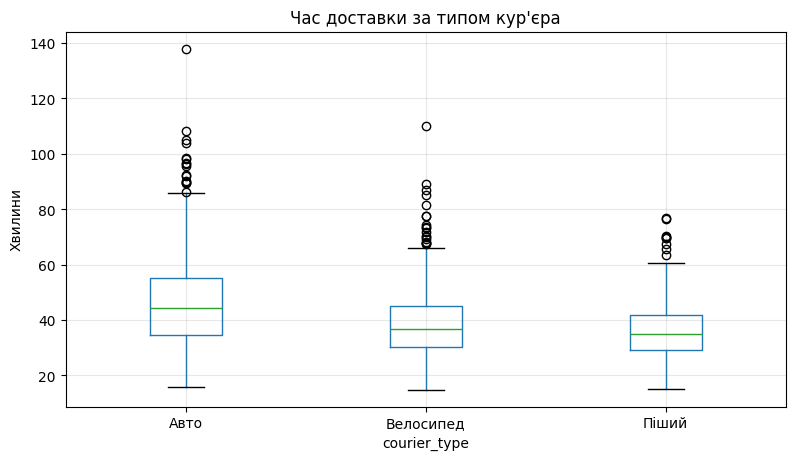

In [57]:
df.boxplot(column='delivery_min', by='courier_type', figsize=(9, 5))
plt.suptitle('')
plt.title('Час доставки за типом кур\'єра')
plt.ylabel('Хвилини')
plt.show()

**✍️ За графіком: у кого найширший «ящик»? У кого найбільше точок-викидів? Чи збігається це з таблицею із завдання 5.4?**

*Ваша відповідь:* _Найширший «ящик» у авто-кур’єрів, тобто в них найбільший розкид середніх 50% часу доставки. Найбільше точок-викидів також у авто-кур’єрів. Це збігається з таблицею із завдання 5.4: у авто-кур’єрів найбільші стандартне відхилення (16,39 хв) та IQR (20,70 хв). Отже, час доставки автомобілем найбільш мінливий, а піші кур’єри доставляють найпередбачуваніше.

---

## Блок 6. Нормальний розподіл (⏱ 20 хв)

Тепер працюємо з іншим датасетом — `packs`: вага 1500 пачок кави, які фасує автомат на фабриці. Норма — 250 г.

**Нагадування:**
- Нормальний розподіл симетричний, середнє = медіана = мода.
- **Правило 68–95–99.7:** у межах ±1σ від середнього лежить ≈68% значень, ±2σ — ≈95%, ±3σ — ≈99.7%.
- **z-оцінка** $z = \frac{x - \mu}{\sigma}$ показує, на скільки стандартних відхилень значення віддалене від середнього.
- `stats.norm.cdf(x, mu, sigma)` — теоретична частка значень, **менших** за x.

### Завдання 6.1. Середнє, відхилення і гістограма

Порахуйте середню вагу пачки та стандартне відхилення. Збережіть у `pack_mean` і `pack_std`. Побудуйте гістограму ваги з 40 інтервалами.

<details>
<summary><b>💡 Підказка 1</b></summary>

`.mean()`, `.std()` і `plt.hist(дані, bins=40)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
pack_mean = packs.mean()
pack_std = packs.std()
plt.hist(packs, bins=40, edgecolor='white')
plt.xlabel('Вага, г')
plt.show()
```

</details>

Середня вага: 249.99 г | Станд. відхилення: 3.07 г


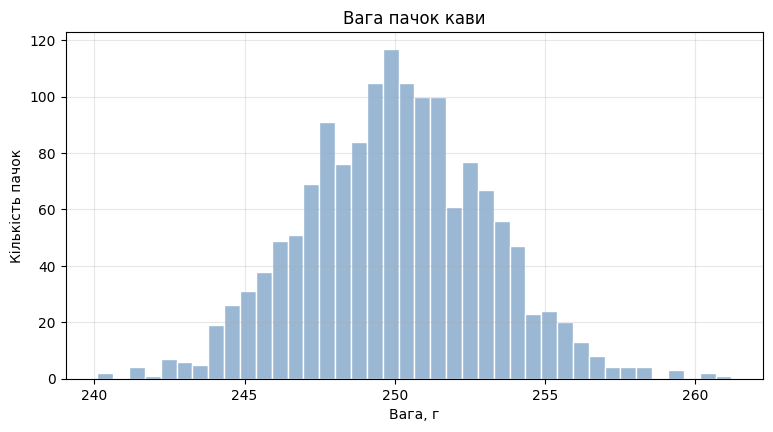

In [59]:
pack_mean = packs.mean()
pack_std = packs.std()

print(f'Середня вага: {pack_mean:.2f} г | Станд. відхилення: {pack_std:.2f} г')

plt.hist(packs, bins=40, color='#9ab7d3', edgecolor='white')
plt.title('Вага пачок кави')
plt.xlabel('Вага, г')
plt.ylabel('Кількість пачок')
plt.show()

In [60]:
check('6.1', pack_mean, pack_std)

✅ Завдання 6.1: правильно! Можна рухатися далі.


### Завдання 6.2. Перевірка правила 68–95–99.7

Порахуйте фактичну частку пачок, вага яких лежить у межах ±1σ, ±2σ і ±3σ від середнього. Збережіть у `share1`, `share2`, `share3`. Порівняйте з теорією.

<details>
<summary><b>💡 Підказка 1</b></summary>

Значення в межах ±1σ: `(packs >= pack_mean - pack_std) & (packs <= pack_mean + pack_std)`. Середнє з такої умови — це частка. Для 2σ і 3σ помножте `pack_std` на 2 і 3.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
share1 = ((packs >= pack_mean - 1 * pack_std) & (packs <= pack_mean + 1 * pack_std)).mean()
```

Скопіюйте рядок і змініть 1 на 2, а потім на 3.

</details>

In [61]:
share1 = ((packs >= pack_mean - 1 * pack_std) & (packs <= pack_mean + 1 * pack_std)).mean()
share2 = ((packs >= pack_mean - 2 * pack_std) & (packs <= pack_mean + 2 * pack_std)).mean()
share3 = ((packs >= pack_mean - 3 * pack_std) & (packs <= pack_mean + 3 * pack_std)).mean()

print(f'±1σ: {share1:.1%}  (теорія ≈ 68.3%)')
print(f'±2σ: {share2:.1%}  (теорія ≈ 95.4%)')
print(f'±3σ: {share3:.1%}  (теорія ≈ 99.7%)')

±1σ: 68.3%  (теорія ≈ 68.3%)
±2σ: 95.6%  (теорія ≈ 95.4%)
±3σ: 99.5%  (теорія ≈ 99.7%)


In [62]:
check('6.2', share1, share2, share3)

✅ Завдання 6.2: правильно! Можна рухатися далі.


### Завдання 6.3. z-оцінка легкої пачки

Контролер знайшов пачку вагою 241 г. Порахуйте її z-оцінку і збережіть у `z_241`.

<details>
<summary><b>💡 Підказка 1</b></summary>

z = (значення − середнє) ÷ стандартне відхилення. Використайте `pack_mean` і `pack_std` із завдання 6.1.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
z_241 = (241 - pack_mean) / pack_std
```

Якщо |z| > 3, значення дуже рідкісне для нормального розподілу (менше 0.3% випадків).

</details>

In [63]:
z_241 = (241 - pack_mean) / pack_std
print(f'z = {z_241:.2f}')

z = -2.93


In [64]:
check('6.3', z_241)

✅ Завдання 6.3: правильно! Можна рухатися далі.


**✍️ Чи нормальна така пачка для цього автомата, чи варто перевірити обладнання? Поясніть через правило 68–95–99.7.**

*Ваша відповідь:* _z-оцінка пачки становить −2,93, тобто її вага на 2,93 стандартного відхилення нижча за середню. За правилом 68–95–99,7 приблизно 95% пачок мають вагу в межах ±2σ, а 99,7% — у межах ±3σ. Отже, пачка вагою 241 г перебуває майже за межами ±3σ і є незвично легкою. Варто перевірити обладнання для фасування, оскільки така вага може свідчити про несправність або помилку фасування.

### Завдання 6.4. Теорія проти фактів: пачки легші за 245 г

Порахуйте теоретичну частку пачок, легших за 245 г (через `stats.norm.cdf`), і фактичну частку в даних. Збережіть у `theor_245` і `actual_245`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`stats.norm.cdf(x, середнє, станд_відхилення)` повертає частку значень, менших за x, для нормального розподілу з такими параметрами. Фактичну частку рахуємо як `(packs < 245).mean()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
theor_245 = stats.norm.cdf(245, pack_mean, pack_std)
actual_245 = (packs < 245).mean()
```

</details>

In [65]:
theor_245 = stats.norm.cdf(245, pack_mean, pack_std)
actual_245 = (packs < 245).mean()

print(f'Теорія: {theor_245:.2%} | Факт: {actual_245:.2%}')

Теорія: 5.20% | Факт: 5.13%


In [66]:
check('6.4', theor_245, actual_245)

✅ Завдання 6.4: правильно! Можна рухатися далі.


---

## Блок 7. Асиметрія і читання гістограм (⏱ 20 хв)

**Нагадування:**
- **Правостороння асиметрія** (skew > 0): довгий хвіст праворуч, середнє > медіана. Приклади: гроші, час.
- **Лівостороння асиметрія** (skew < 0): довгий хвіст ліворуч, середнє < медіана. Приклад: оцінки, де більшість ставить 4–5.
- Асиметрію називають **за хвостом**.

**6 питань до будь-якої гістограми:** центр · розкид · форма · кількість піків · викиди і прогалини · неможливі значення.

### Завдання 7.1. Асиметрія всіх числових колонок

Порахуйте коефіцієнт асиметрії для колонок `order_sum`, `delivery_min`, `distance_km`, `tip_uah`, `items`, `rating`. Збережіть у `left_col` назву колонки з **від'ємною** асиметрією.

<details>
<summary><b>💡 Підказка 1</b></summary>

Метод `.skew()` можна викликати одразу для кількох колонок: `df[[список колонок]].skew()`. Подвійні квадратні дужки означають «вибрати кілька колонок».

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
skews = df[['order_sum', 'delivery_min', 'distance_km', 'tip_uah', 'items', 'rating']].skew()
left_col = skews.idxmin()
```

`.idxmin()` повертає назву колонки з найменшим (найбільш від'ємним) значенням.

</details>

In [67]:
skews = df[['order_sum', 'delivery_min', 'distance_km', 'tip_uah', 'items', 'rating']].skew()
print(skews.round(2))

left_col = skews.idxmin()
print('Лівостороння асиметрія:', left_col)

order_sum       1.55
delivery_min    1.29
distance_km     1.38
tip_uah         1.79
items           0.75
rating         -1.07
dtype: float64
Лівостороння асиметрія: rating


In [68]:
check('7.1', left_col)

✅ Завдання 7.1: правильно! Можна рухатися далі.


### Завдання 7.2. Гістограма суми замовлення

Побудуйте гістограму `order_sum` (50 інтервалів) і додайте дві вертикальні лінії: червону пунктирну для середнього і зелену для медіани.

<details>
<summary><b>💡 Підказка 1</b></summary>

Вертикальна лінія: `plt.axvline(значення, color='red', linestyle='--', label='...')`. Щоб показати підписи, викличте `plt.legend()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
s = df['order_sum']
plt.hist(s, bins=50, color='#9ab7d3', edgecolor='white')
plt.axvline(s.mean(), color='red', linestyle='--', label='Середнє')
plt.axvline(s.median(), color='green', label='Медіана')
plt.legend()
plt.show()
```

</details>

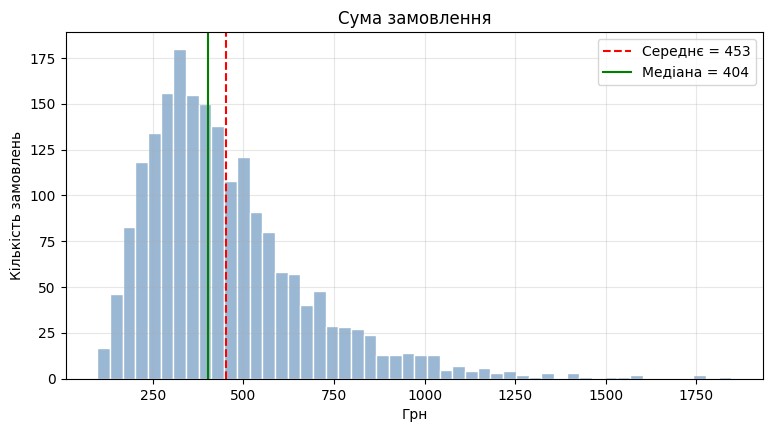

In [69]:
s = df['order_sum']
plt.hist(s, bins=50, color='#9ab7d3', edgecolor='white')
plt.axvline(s.mean(), color='red', linestyle='--', label=f'Середнє = {s.mean():.0f}')
plt.axvline(s.median(), color='green', label=f'Медіана = {s.median():.0f}')
plt.title('Сума замовлення')
plt.xlabel('Грн')
plt.ylabel('Кількість замовлень')
plt.legend()
plt.show()

**✍️ Який тип асиметрії ви бачите? З якого боку хвіст? Яка лінія ближча до «горба» гістограми?**

*Ваша відповідь:* _Тип асиметрії -правостороння (позитивна), оскільки довгий хвіст тягнеться вправо, у бік більших сум замовлень. Зелена лінія медіани (404 грн) ближча до «горба» гістограми, ніж червона лінія середнього (453 грн). Середнє більше за медіану через вплив великих замовлень у правому хвості.

### Завдання 7.3. Вплив кількості інтервалів ⭐ *бонус*

Побудуйте три гістограми `delivery_min` поруч: з 5, 30 і 300 інтервалами.

<details>
<summary><b>💡 Підказка 1</b></summary>

Створіть три графіки в одному рядку: `fig, axes = plt.subplots(1, 3, figsize=(15, 4))`. Потім у циклі малюйте на кожному `ax.hist(...)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, b in zip(axes, [5, 30, 300]):
    ax.hist(df['delivery_min'], bins=b, color='#9ab7d3', edgecolor='white')
    ax.set_title(f'bins = {b}')
plt.tight_layout()
plt.show()
```

</details>

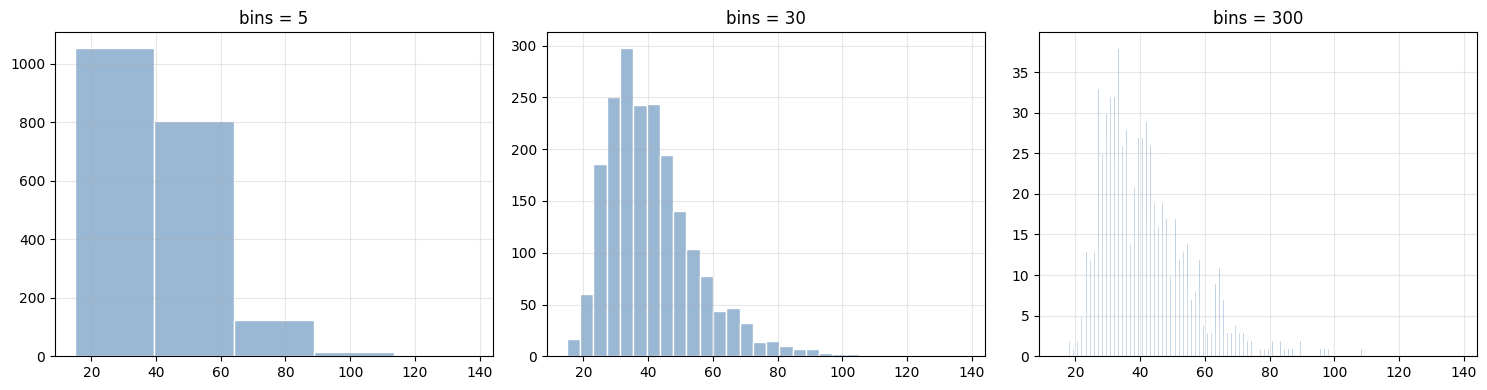

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, b in zip(axes, [5, 30, 300]):
    ax.hist(df['delivery_min'], bins=b, color='#9ab7d3', edgecolor='white')
    ax.set_title(f'bins = {b}')

plt.tight_layout()
plt.show()

**✍️ На якій гістограмі форму розподілу видно найкраще? Що не так з двома іншими?**

*Ваша відповідь:* _Найкраще форму розподілу видно на гістограмі з 30 інтервалами: вона показує основну форму розподілу та його правосторонню асиметрію. На гістограмі з 5 інтервалами замало деталей, тому особливості розподілу приховані. На гістограмі з 300 інтервалами забагато вузьких стовпчиків, через що вона виглядає дуже нерівною та її важче інтерпретувати.

### Завдання 7.4. Два піки: коли замовляють їжу

Побудуйте гістограму `order_hour` (час замовлення). Знайдіть годину з найбільшою кількістю замовлень **до 16:00** і **після 16:00**. Збережіть у `lunch_peak` і `dinner_peak` (цілі числа годин).

<details>
<summary><b>💡 Підказка 1</b></summary>

1. Створіть цілу годину: `df['order_hour'].astype(int)` (наприклад, 13.75 → 13).
2. Окремо для замовлень до 16 і після 16 знайдіть моду цієї цілої години.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
hour_int = df['order_hour'].astype(int)
lunch_peak = hour_int[hour_int < 16].mode()[0]
dinner_peak = hour_int[hour_int >= 16].mode()[0]
```

</details>

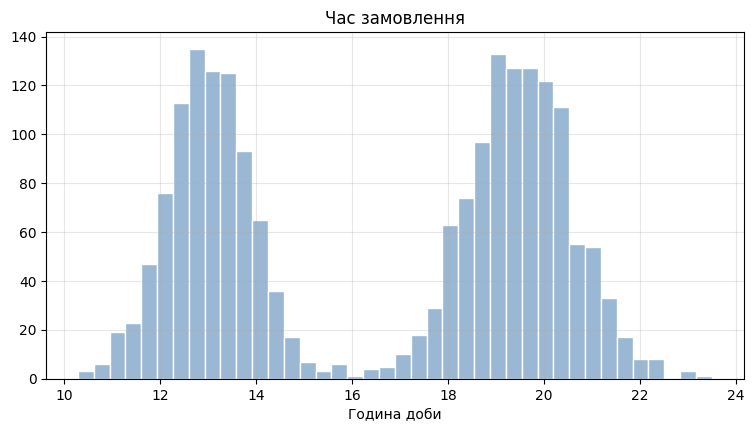

Пік обіду: 13 | Пік вечері: 19
Середній час замовлення: 16.6


In [71]:
plt.hist(df['order_hour'], bins=40, color='#9ab7d3', edgecolor='white')
plt.title('Час замовлення')
plt.xlabel('Година доби')
plt.show()

hour_int = df['order_hour'].astype(int)

lunch_peak = hour_int[hour_int < 16].mode()[0]
dinner_peak = hour_int[hour_int >= 16].mode()[0]

print('Пік обіду:', lunch_peak, '| Пік вечері:', dinner_peak)
print(f'Середній час замовлення: {df["order_hour"].mean():.1f}')

In [72]:
check('7.4', lunch_peak, dinner_peak)

✅ Завдання 7.4: правильно! Можна рухатися далі.


**✍️ Середній час замовлення — близько 16:35 (16.6 год). Чи багато замовлень саме о цій годині? Чому середнє тут вводить в оману?**

*Ваша відповідь:* _Ні, о 16:35 замовлень небагато — на гістограмі видно спад між двома піками: обіднім (близько 13:00) і вечірнім (близько 19:00–20:00). Середнє вводить в оману, тому що розподіл має два піки (є бімодальним). Середній час близько 16:35 лежить між ними й не відображає жоден із двох основних періодів активності.

### Завдання 7.5. Чек-лист для гістограми часу доставки

Подивіться ще раз на гістограму `delivery_min` (з 30 інтервалами із завдання 7.3 або побудуйте нову) і дайте відповідь на 6 питань чек-листа в клітинці нижче.

<details>
<summary><b>💡 Підказка 1</b></summary>

Пройдіться по пунктах: де центр (медіана)? Наскільки широко розкидані значення? Чи є хвіст і з якого боку? Скільки піків? Чи є окремі далекі значення? Чи є неможливі значення (менше 0)?

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Потрібні числа можна взяти з `df['delivery_min'].describe()` і `df['delivery_min'].skew()`.

</details>

In [74]:
df['delivery_min'].describe()
df['delivery_min'].skew().round(2)

np.float64(1.29)

**✍️ 1) Центр: … 2) Розкид: … 3) Форма: … 4) Піки: … 5) Викиди: … 6) Неможливі значення: …**

*Ваша відповідь:* _
1\) Центр: медіана — близько 38 хвилин, середнє — близько 40 хвилин. 2) Розкид: стандартне відхилення — 14 хвилин, IQR — 16,7 хвилини. 3) Форма: правостороння асиметрія, `skew = 1.29`. 4) Піки: найбільше замовлень зосереджено приблизно в діапазоні 30–45 хвилин. 5) Викиди: є потенційні викиди у вигляді дуже тривалих доставок. 6) Неможливі значення: варто перевірити, чи немає нульових або від’ємних значень часу доставки, оскільки вони можуть свідчити про помилки в даних.

---

## Блок 8. Підсумкове завдання: міні-звіт (⏱ 15 хв)

Уявіть, що менеджер просить коротко описати **відстань доставки** (`distance_km`). Зберіть усе, чого навчились, в один звіт.

### Завдання 8.1. Міні-звіт про відстань доставки

У клітинці з кодом порахуйте всі потрібні показники для `distance_km` і побудуйте гістограму. Потім у текстовій клітинці напишіть звіт для менеджера з 4–6 речень **простою мовою**, без термінів на кшталт «дисперсія».

<details>
<summary><b>💡 Підказка 1</b></summary>

Порахуйте: середнє, медіану, стандартне відхилення, Q1, Q3, p90, мінімум, максимум, асиметрію. Подумайте, чи є різниця між піхотою та іншими кур'єрами.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Корисні рядки:

```python
dist = df['distance_km']
print(dist.describe())
print('p90:', dist.quantile(0.9))
print('skew:', dist.skew())
print(df.groupby('courier_type')['distance_km'].median())
```

У звіті: «Типова відстань — … км. Половина замовлень — від … до … км. 10% замовлень їдуть далі за … км. …»

</details>

Кількість замовлень: 2000
Середня відстань: 3.12 км
Медіана: 2.6 км
Стандартне відхилення: 2.16 км
Мінімум: 0.3 км
Максимум: 17.6 км
25-й і 75-й процентилі:
0.25   1.50
0.75   4.20
Name: distance_km, dtype: float64
Асиметрія: 1.38


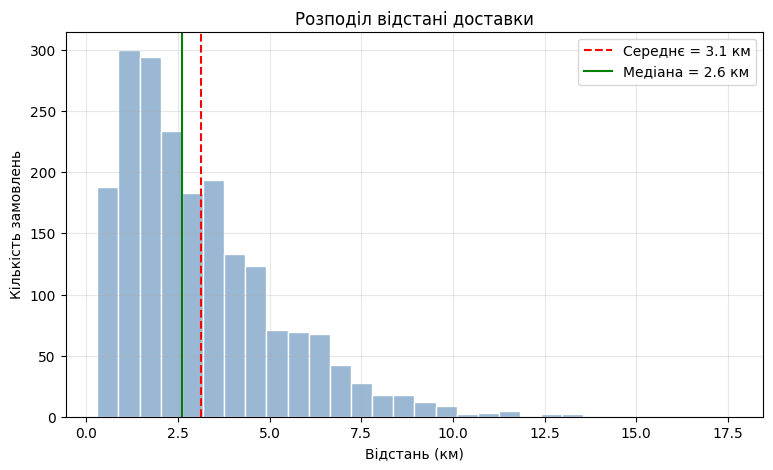


Відстань за типом кур’єра:
              count  mean  median  std  min   max
courier_type                                     
Авто            725  3.58    3.20 2.18 0.40 15.90
Велосипед       905  3.50    3.00 2.15 0.40 17.60
Піший           370  1.28    1.10 0.74 0.30  4.60


In [76]:
dist = df['distance_km']

# Ваш код: статистики, гістограма, порівняння за типом кур'єра
import matplotlib.pyplot as plt


# Основні статистики
print('Кількість замовлень:', dist.count())
print('Середня відстань:', round(dist.mean(), 2), 'км')
print('Медіана:', round(dist.median(), 2), 'км')
print('Стандартне відхилення:', round(dist.std(), 2), 'км')
print('Мінімум:', round(dist.min(), 2), 'км')
print('Максимум:', round(dist.max(), 2), 'км')
print('25-й і 75-й процентилі:')
print(dist.quantile([0.25, 0.75]))
print('Асиметрія:', round(dist.skew(), 2))

# Гістограма
plt.figure(figsize=(9, 5))
plt.hist(dist.dropna(), bins=30, color='#9ab7d3', edgecolor='white')
plt.axvline(dist.mean(), color='red', linestyle='--',
            label=f'Середнє = {dist.mean():.1f} км')
plt.axvline(dist.median(), color='green',
            label=f'Медіана = {dist.median():.1f} км')
plt.title('Розподіл відстані доставки')
plt.xlabel('Відстань (км)')
plt.ylabel('Кількість замовлень')
plt.legend()
plt.show()

# Порівняння за типом кур'єра
print('\nВідстань за типом кур’єра:')
print(df.groupby('courier_type')['distance_km'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2))

**✍️ Звіт для менеджера (4–6 речень):**

*Ваша відповідь:* _Ось готовий міні-звіт для менеджера на основі твоїх результатів:

Міні-звіт про відстань доставки

У середньому відстань доставки становить 3,12 км, а половина замовлень доставляється на відстань до 2,6 км. Найчастіше трапляються короткі маршрути, але є й поодинокі далекі доставки — до 17,6 км. Близько половини замовлень мають відстань від 1,5 до 4,2 км. Піші кур’єри обслуговують значно коротші маршрути — у середньому 1,28 км, тоді як для велосипедних кур’єрів середнє становить 3,50 км, а для автомобільних — 3,58 км. Розподіл має довгий хвіст у бік більших відстаней, тому середнє значення вище за медіану. Для ефективнішої роботи варто враховувати відстань під час розподілу замовлень між типами кур’єрів.

---
## 🎉 Готово!

Ви пройшли всі теми: типи ознак, середнє, медіану, моду, квантилі, викиди, міри розсіювання, нормальний розподіл, асиметрію і читання гістограм.

**Перед здачею:** *Runtime → Restart and run all* (у Colab) — переконайтеся, що весь блокнот запускається зверху вниз без помилок.